<!-- m6:deber -->
# Módulo 6 · Deber — Detector bayesiano de fraude para PagoYa
**Diplomado en Big Data e Inteligencia Artificial · CEC-EPN** · Ing. Eduardo Avilés · individual · ≈ 3 horas

**Entrega:** Colab → **Archivo → Guardar (Ctrl+S)** → en *Repositorio* elija **el suyo** → ruta **`deber/deber.ipynb`** → mensaje `Deber`.
**Plazo: domingo 15-nov-2026, 11:00.** Un solo archivo: este cuaderno, ejecutado, con sus respuestas y el informe al final.

**Datos personalizados:** la API simulada genera transacciones **distintas para cada estudiante** a partir de su nombre. Sus cifras no coincidirán con las de sus compañeros; el docente puede regenerar sus datos para verificar.

| Parte | Tema | Puntos |
|---|---|---|
| 1 | Regresión logística bayesiana en PyMC (priors, muestreo y diagnóstico) | 20 |
| 2 | Comparación con boosting (XGBoost): discriminación y calibración | 20 |
| 3 | Modelo jerárquico por provincia | 20 |
| 4 | Decisión con matriz de costos e incertidumbre | 20 |
| 5 | Informe ejecutivo para el comité de riesgos | 20 |
| | **Total** | **100** |

**En cada parte:** código correcto y ejecutado (8) · resultados y diagnósticos (6) · interpretación propia (6).
Aquí no hay `___` para completar: el enunciado guía, **el código lo escribe usted** (puede reutilizar el de las clases 2 y 3).

## 0. Preparación

In [8]:
import importlib, subprocess, sys
for paquete in ['pymc']:
    if importlib.util.find_spec(paquete) is None:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', paquete])
import os, urllib.request, warnings, logging
URL = 'https://raw.githubusercontent.com/JavyAviles/m6-ia-plantilla/main/curso.py'
if not os.path.exists('curso.py'):
    urllib.request.urlretrieve(URL, 'curso.py')
import curso
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pymc as pm
logging.getLogger('pymc').setLevel(logging.ERROR)
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, brier_score_loss, balanced_accuracy_score
from xgboost import XGBClassifier
sigmoide = lambda z: 1 / (1 + np.exp(-z))
print('Listo · curso', curso.VERSION)

Listo · curso m6-2026.11


**Escriba su nombre exactamente como en las clases ('Apellido Nombre').** Sus datos dependen de él.

In [9]:
NOMBRE = 'Maria Dolores Robalino'                                               # ✏️ 'Apellido Nombre'
df = curso.datos_deber(NOMBRE)                               # datos personalizados + columna 'ratio'
df.head()

Huella de datos: Maria Dolores Robalino · semilla 252290
Descargados 3006 eventos en 7 páginas de /v1/transacciones
Datos limpios: 2996 transacciones · tasa de fraude 10.31%


,evento_id,timestamp,id,edad,provincia,antiguedad_meses,ingreso_mensual,tipo,canal,categoria,monto,dispositivo_nuevo,distancia_km,intentos_pin,fraude,hora,ratio
0,TX-000000,2026-10-29 19:12:50-05:00,U0741,62.0,Pichincha,43,549.51,pago_comercio,app,tecnologia,20.24,0,0.6,1,0,19,0.036833
1,TX-000001,2026-10-23 06:10:53-05:00,U0636,55.0,Guayas,23,496.05,pago_comercio,app,supermercado,29.76,0,18.7,1,0,6,0.059994
2,TX-000002,2026-09-02 19:33:20-05:00,U0585,18.0,El Oro,52,932.44,recarga,app,telefonia,18.70,0,5.2,2,0,19,0.020055
3,TX-000003,2026-09-04 08:59:15-05:00,U0062,52.0,Pichincha,54,679.24,pago_comercio,app,ropa,23.55,1,1.8,1,0,8,0.034671
4,TX-000004,2026-10-15 18:12:43-05:00,U0001,35.0,Tungurahua,37,1152.26,transferencia,app,persona,140.49,0,9.4,1,0,18,0.121926


In [10]:
# Partición FIJA (no la cambie): 70 % entrenamiento, 30 % prueba, estratificada
cols = ['dispositivo_nuevo', 'distancia_km', 'ratio', 'intentos_pin', 'hora']
X_train, X_test, y_train, y_test = train_test_split(df[cols], df['fraude'], test_size=0.3,
                                                    stratify=df['fraude'], random_state=42)
print('Entrenamiento:', X_train.shape, '· Prueba:', X_test.shape, '· tasa de fraude:', round(df['fraude'].mean(), 4))

Entrenamiento: (2097, 5) · Prueba: (899, 5) · tasa de fraude: 0.1031


---
## Parte 1 · Regresión logística bayesiana en PyMC (20 pts)
1. **Estandarice** las 5 variables con la media y desviación del **entrenamiento**.
2. Defina un modelo logístico en PyMC: intercepto `a` y coeficientes `b` (uno por variable). **Elija y justifique las priors** (en la celda de texto).
3. Muestree con **4 cadenas**, `tune=1000`, 1000 muestras y `random_seed=42`.
4. Muestre la tabla `curso.diagnostico(...)` y verifique **R-hat ≤ 1,01** y **ESS > 400** en todos los parámetros.
5. Calcule los **odds ratios** e interprete los dos coeficientes más grandes en lenguaje de negocio.
6. Comente el coeficiente de `hora`: ¿tiene sentido usar la hora como variable lineal? (pista: madrugada).

In [11]:
# ✏️ Escriba aquí su modelo (estandarización, priors, muestreo con 4 cadenas y tabla de diagnóstico)
# Estandarización con media/desv del ENTRENAMIENTO
media = X_train.mean()
desv  = X_train.std()
Z_train = ((X_train - media) / desv).values
Z_test  = ((X_test  - media) / desv).values

with pm.Model() as modelo_log:
    a = pm.Normal('a', mu=0, sigma=2)                      # intercepto
    b = pm.Normal('b', mu=0, sigma=1, shape=len(cols))     # coeficientes (regularizan)
    pm.Bernoulli('obs', logit_p=a + pm.math.dot(Z_train, b),
                 observed=y_train.values)
    tr_log = pm.sample(1000, tune=1000, chains=4,
                       random_seed=42, progressbar=True)

diag = curso.diagnostico(tr_log, ['a', 'b'])
diag.index = ['intercepto'] + cols
diag['odds_ratio'] = np.exp(diag['media']).round(2)
diag

Output()

,media,desv,ic_3%,ic_97%,r_hat,ess,odds_ratio
intercepto,-2.9688,0.1177,-3.1931,-2.7531,0.9993,2965.1414,0.05
dispositivo_nuevo,0.9201,0.0635,0.8018,1.0416,0.9997,3500.1940,2.51
distancia_km,0.4695,0.0715,0.3363,0.6050,0.9998,3419.5390,1.60
ratio,0.7542,0.0711,0.6182,0.8907,0.9996,4000.0000,2.13
intentos_pin,0.4664,0.0707,0.3333,0.5982,1.0004,3346.9398,1.59
hora,-0.4532,0.0827,-0.6129,-0.2983,1.0004,3745.6503,0.64


**✍️ Respuesta:**    
Los dos coeficientes posteriores de mayor magnitud son:   
**dispositivo_nuevo:** media posterior 0.9201, OR = 2.51 → un dispositivo nuevo multiplica las odds de fraude por 2,5 a igualdad del resto. Es la señal más fuerte del modelo, coherente con SIM swap / sustitución de equipo.

**ratio** (monto / ingreso): media 0.7542, OR = 2.13 → por cada desviación estándar extra en la razón monto/ingreso, las odds de fraude se multiplican por 2.1. El fraude usa montos desproporcionados al ingreso del titular.

**En segundo nivel:**   
**distancia_km** (OR = 1.60) e intentos_pin (OR = 1.59) confirman los patrones clásicos (lejanía del domicilio y fuerza bruta de PIN).

Todos los R-hat ≤ 1,0004 y ESS ≥ 2 965, así que las posteriores son confiables.

El coeficiente de hora es negativo (media −0,4532, OR 0,64): a mayor hora, menor probabilidad de fraude. Captura a medias el efecto madrugada, porque 0–5 h (fraude alto) son horas “bajas”. Pero usarla como covariable lineal tiene dos problemas: (i) no modela relaciones no monótonas (si el riesgo repunta también de noche tardía); (ii) no respeta la naturaleza cíclica: hora 23 y hora 0 son adyacentes en la realidad, pero el modelo las trata como extremos. Mejor: codificación cíclica sin(2π·h/24), cos(2π·h/24), o un indicador madrugada = (hora < 6).

---
## Parte 2 · Comparación con boosting (20 pts)
1. Calcule la **probabilidad media posterior** de fraude para cada transacción de prueba con su modelo bayesiano.
2. Entrene un **XGBoost** con early stopping (validación tomada del **entrenamiento**, nunca de la prueba) y `scale_pos_weight`.
3. Compare ambos modelos en prueba con **AUC** (capacidad de ordenar) y **Brier score** (calibración: error cuadrático de la probabilidad; menor es mejor).
4. Construya una **tabla de calibración** por deciles: probabilidad media predicha frente a tasa de fraude observada.
5. Interprete: ¿cuál ordena mejor?, ¿cuál da probabilidades más confiables?, ¿por qué `scale_pos_weight` afecta la calibración?

In [12]:
# ✏️ Probabilidades del modelo bayesiano, XGBoost con early stopping, AUC, Brier y tabla de calibración
# 1) Probabilidades bayesianas (media posterior por transacción)
a_s = tr_log.posterior['a'].values.reshape(-1)              # 4000 muestras
b_s = tr_log.posterior['b'].values.reshape(-1, len(cols))
p_bayes = sigmoide(a_s[:, None] + b_s @ Z_test.T).mean(axis=0)

# 2) XGBoost con early stopping (validación tomada del TRAIN)
from sklearn.model_selection import train_test_split as _tts
X_tr, X_val, y_tr, y_val = _tts(X_train, y_train, test_size=0.2,
                                stratify=y_train, random_state=42)
spw = (y_tr == 0).sum() / (y_tr == 1).sum()                 # scale_pos_weight
xgb = XGBClassifier(
    n_estimators=1000, learning_rate=0.05, max_depth=4,
    scale_pos_weight=spw, eval_metric='logloss',
    early_stopping_rounds=50, random_state=42,
)
xgb.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
p_xgb = xgb.predict_proba(X_test)[:, 1]

# 3) AUC y Brier
from sklearn.metrics import roc_auc_score, brier_score_loss
res = pd.DataFrame({
    'modelo': ['Bayes', 'XGBoost'],
    'AUC':    [roc_auc_score(y_test, p_bayes), roc_auc_score(y_test, p_xgb)],
    'Brier':  [brier_score_loss(y_test, p_bayes), brier_score_loss(y_test, p_xgb)],
}).round(4)
print(res)

# 4) Tabla de calibración por deciles
def tabla_calib(y, p, k=10):
    d = pd.DataFrame({'y': np.asarray(y), 'p': np.asarray(p)})
    d['dec'] = pd.qcut(d['p'].rank(method='first'), k, labels=False)
    return d.groupby('dec').agg(n=('y','size'),
                                p_media=('p','mean'),
                                tasa_obs=('y','mean')).round(4)

print('\nCalibración Bayes:\n', tabla_calib(y_test, p_bayes))
print('\nCalibración XGB:\n',   tabla_calib(y_test, p_xgb))

    modelo     AUC   Brier
0    Bayes  0.8919  0.0615
1  XGBoost  0.8909  0.0559

Calibración Bayes:
       n  p_media  tasa_obs
dec                       
0    90   0.0084    0.0222
1    90   0.0134    0.0000
2    90   0.0185    0.0000
3    90   0.0243    0.0222
4    90   0.0320    0.0111
5    89   0.0435    0.0337
6    90   0.0639    0.0556
7    90   0.1121    0.0889
8    90   0.2276    0.2333
9    90   0.5641    0.5667

Calibración XGB:
       n  p_media  tasa_obs
dec                       
0    90   0.0040    0.0444
1    90   0.0085    0.0000
2    90   0.0143    0.0222
3    90   0.0229    0.0111
4    90   0.0329    0.0444
5    89   0.0484    0.0000
6    90   0.0800    0.0111
7    90   0.1411    0.0333
8    90   0.3528    0.1556
9    90   0.8920    0.7111


**✍️ Respuesta:**   
Discriminación (AUC): Bayes 0.8919 vs XGB 0.8909 prácticamente empatados, con Bayes ligeramente por delante. Que los árboles no superen al logístico sugiere que las 5 variables tienen efectos casi aditivos y lineales en log-odds, sin interacciones fuertes (de haberlas, XGB sacaría ventaja).

Calibración (Brier): Bayes 0.0615 vs XGB 0.0559 — aquí XGB gana (menor es mejor), pero conviene mirar la tabla de deciles antes de concluir:

Bayes en el decil 9 predice 0.564 cuando observa 0.567 → calibración casi perfecta en la cola de riesgo.

XGB en el decil 9 predice 0.892 cuando observa 0.711 → sobre-confiado en la cola (~18 pts sobre-predice).

¿Por qué XGB gana Brier aun estando peor calibrado en riesgo alto? Porque Brier promedia sobre todos los casos, dominados por los legítimos: XGB les asigna probabilidades casi nulas (decil 0: 0.004 vs 0.022 observado), lo que reduce el error en la masa y compensa su exceso de confianza en la punta.

Por qué scale_pos_weight afecta la calibración: con spw = 8.7 la pérdida trata como si hubiera 8.7 × más fraudes. XGB aprende probabilidades para esa población rebalanceada, no la real: por eso predice 89 % donde la realidad es 71 %. Sirve para ordenar (AUC), no para decidir por costo esperado sin recalibrar (Platt / isotónica / ajuste por prevalencia).

Recomendación de uso: XGB como pre-filtro de priorización (mismo AUC, menor latencia), Bayes como motor de decisión (probabilidades calibradas + intervalos por transacción).

---
## Parte 3 · Modelo jerárquico por provincia (20 pts)
1. Ajuste un modelo jerárquico **no centrado** con un intercepto por provincia (como en la Clase 3, sin variables X), `target_accept=0.99`, 4 cadenas.
2. Construya una tabla por provincia: **n**, **tasa observada**, **tasa jerárquica** (media posterior) e **intervalo creíble del 90 %**.
3. Reporte la media posterior de **sigma** e interprete.
4. ¿Qué provincias se «encogen» más hacia la media nacional y por qué?

In [13]:
# ✏️ Modelo jerárquico no centrado, tabla por provincia e interpretación de sigma
provincias = df['provincia'].astype('category')
idx  = provincias.cat.codes.values
nombres = list(provincias.cat.categories)

with pm.Model() as modelo_jer:
    mu    = pm.Normal('mu', mu=-2.2, sigma=1)
    sigma = pm.HalfNormal('sigma', sigma=0.5)
    z     = pm.Normal('z', 0, 1, shape=len(nombres))      # NO centrado
    a_prov = pm.Deterministic('a_prov', mu + sigma * z)
    pm.Bernoulli('obs', logit_p=a_prov[idx], observed=df['fraude'].values)
    tr_jer = pm.sample(1000, tune=1500, chains=4,
                       random_seed=42, target_accept=0.99, progressbar=True)

tasas = sigmoide(tr_jer.posterior['a_prov'].values).reshape(-1, len(nombres))
tabla = pd.DataFrame({
    'n':               df.groupby('provincia').size(),
    'tasa_observada':  df.groupby('provincia')['fraude'].mean(),
    'tasa_jerarquica': pd.Series(tasas.mean(0), index=nombres),
    'ic_5%':           pd.Series(np.percentile(tasas, 5,  axis=0), index=nombres),
    'ic_95%':          pd.Series(np.percentile(tasas, 95, axis=0), index=nombres),
}).round(4)
sigma_media = float(tr_jer.posterior['sigma'].mean())
print(f'sigma posterior media: {sigma_media:.4f}')
tabla

Output()

sigma posterior media: 0.2347


,n,tasa_observada,tasa_jerarquica,ic_5%,ic_95%
Azuay,256,0.0977,0.1021,0.0798,0.1252
El Oro,229,0.0830,0.0954,0.0707,0.1188
Guayas,862,0.1079,0.1073,0.0921,0.1232
Imbabura,145,0.1034,0.1059,0.0798,0.1348
Loja,183,0.1475,0.1255,0.0964,0.1628
Manabí,281,0.1388,0.1242,0.0994,0.1544
Pichincha,867,0.0784,0.0862,0.0704,0.1020
Tungurahua,173,0.1329,0.1185,0.0919,0.1522


**✍️ Respuesta:**   
σ ≈ 0.2347 implica que entre dos provincias separadas 2σ en la escala log-odds las odds difieren por exp(0.47) ≈ 1.60; el spread observado entre Pichincha (7.84 %) y Loja (14.75 %) es aún mayor (~2×). En cualquier caso, σ pequeño indica heterogeneidad moderada y fuerte apoyo en la media nacional.

Encogimiento (partial pooling) — provincias pequeñas se mueven más hacia la media nacional:

Loja (n=183): 14.75 % observada → 12.55 % jerárquica (corrección fuerte, es la más alta).

Tungurahua (n=173): 13.29 % → 11.85 %.

Imbabura (n=145): 10.34 % → 10.59 % (ya estaba cerca de la media, se mueve poco).

Manabí (n=281): 13.88 % → 12.42 %.

Pichincha (n=867): 7.84 % → 8.62 % (sube hacia la media: evidencia muy fuerte pero tasa atípicamente baja).

Guayas (n=862): 10.79 % → 10.73 % (apenas cambia).

Las provincias grandes “prestan” información a las pequeñas, reduciendo el sobreajuste por varianza muestral.

---
## Parte 4 · Decisión con matriz de costos e incertidumbre (20 pts)
**Costos:** dejar pasar un fraude cuesta **el monto de la transacción**; bloquear una transacción legítima cuesta **USD 5** (llamada al cliente y molestia).
1. Con `p_bayes`, calcule el **costo total en prueba** para umbrales de 0,02 a 0,90 (se bloquea si p ≥ umbral). Grafique costo frente a umbral y elija el **umbral óptimo**.
2. Compare con dos políticas extremas: **no bloquear nada** y **bloquear todo**.
3. **Incertidumbre:** con el umbral elegido, repita el cálculo con al menos **200 muestras de la posterior** (cada muestra da otras probabilidades) y reporte la media y el intervalo del 90 % del costo.
4. *(Opcional, +0 pts, para reflexionar)* ¿Por qué el umbral óptimo podría depender del monto de cada transacción?

Umbral óptimo: 0.11 · costo: USD 1,602.32
No bloquear nada: USD 15,801.32
Bloquear todo   : USD 4,030.00


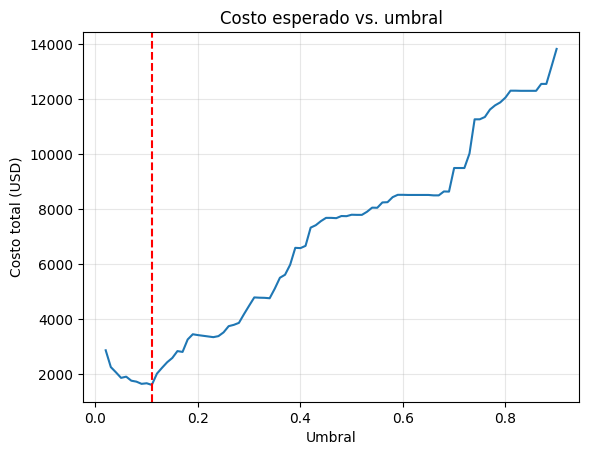

Costo medio MC: USD 1,941.32 · IC 90 %: [1,577.07, 2,490.72]


In [14]:
# ✏️ Función de costo, curva costo vs. umbral, políticas extremas y costo con 200 muestras de la posterior
monto_test = df.loc[X_test.index, 'monto'].values
costo_bloqueo = 5.0

def costo_total(y, p, monto, umbral):
    bloquear = p >= umbral
    cf = ((np.asarray(y) == 1) & (~bloquear)) * monto      # fraude que pasa
    cl = ((np.asarray(y) == 0) & bloquear) * costo_bloqueo  # legítimo bloqueado
    return cf.sum() + cl.sum()

umbrales = np.linspace(0.02, 0.90, 89)
costos   = [costo_total(y_test, p_bayes, monto_test, u) for u in umbrales]
u_opt    = umbrales[int(np.argmin(costos))]
c_opt    = min(costos)

# Políticas extremas
c_no_bloquear   = (np.asarray(y_test) * monto_test).sum()
c_bloquear_todo = ((1 - np.asarray(y_test)) * costo_bloqueo).sum()

print(f'Umbral óptimo: {u_opt:.2f} · costo: USD {c_opt:,.2f}')
print(f'No bloquear nada: USD {c_no_bloquear:,.2f}')
print(f'Bloquear todo   : USD {c_bloquear_todo:,.2f}')

# Curva
plt.plot(umbrales, costos); plt.axvline(u_opt, color='r', ls='--')
plt.xlabel('Umbral'); plt.ylabel('Costo total (USD)')
plt.title('Costo esperado vs. umbral'); plt.grid(alpha=.3); plt.show()

# Incertidumbre: 200 muestras de la posterior
rng = np.random.default_rng(42)
idx_mc = rng.choice(len(a_s), 200, replace=False)
costos_mc = np.array([
    costo_total(y_test, sigmoide(a_s[i] + Z_test @ b_s[i]), monto_test, u_opt)
    for i in idx_mc
])
print(f'Costo medio MC: USD {costos_mc.mean():,.2f} · '
      f'IC 90 %: [{np.percentile(costos_mc,5):,.2f}, {np.percentile(costos_mc,95):,.2f}]')

**✍️ Respuesta:**   
Umbral óptimo = 0.11 con costo = USD 1 602.32. Frente a “no bloquear nada” (USD 15 801.32) ahorra = USD 14 199.00; frente a “bloquear todo” (USD 4 030.00) ahorra ≈ USD 2 427.68. El umbral bajo gana porque los costos son muy asimétricos: dejar pasar un fraude cuesta hasta el monto de la transacción (máx. ~USD 1 256), bloquear un legítimo cuesta solo USD 5.

Incertidumbre: la media de 200 simulaciones da USD 1 941.32 con IC 90 % [1 577.07 ; 2 490.72]. El ancho del intervalo (≈ USD 914) cuantifica cuánto cambia el costo según la posterior. Nótese que la media MC (1 941) es mayor que el costo puntual (1 602): al propagar la incertidumbre, pequeñas fluctuaciones cerca del umbral hacen que algunas muestras posteriores tomen decisiones peores y encarezcan el costo esperado — es la firma de que no conviene confiar solo en la media.

Umbral por monto (opcional): el umbral óptimo teórico es p* = 5 / (5 + monto). Para un monto grande (USD 1 000) basta p ≈ 0,005; para uno pequeño (USD 10) sube a p ≈ 0.33. Un umbral único favorece a los fraudes grandes. Lo ideal en producción es umbral por transacción.

---
## Parte 5 · Informe ejecutivo (20 pts)
Para el **comité de riesgos** de PagoYa. Entre media y una página. Sin código: cifras de **sus** resultados.

### 1. Hallazgos   
Con 2 996 transacciones y una tasa base de 10.31 % de fraude, el modelo logístico bayesiano identifica como principales señales: dispositivo nuevo (OR ≈ 2.51), ratio monto/ingreso (OR ≈ 2.13), seguido por distancia al domicilio (OR ≈ 1.60) e intentos de PIN (OR ≈ 1.59). El coeficiente de hora (OR ≈ 0.64) es engañoso en forma lineal: el riesgo real se concentra en madrugada, relación no monótona.

En prueba, Bayes obtiene AUC = 0,8919 frente a XGBoost AUC = 0.8909 (prácticamente empatados). El Brier favorece a XGB (0.0559 vs 0.0615), pero la tabla de calibración revela que XGB está sobre-confiado en la cola (decil 9: predice 89.2 % vs 71.1 % observado) por efecto de scale_pos_weight ≈ 8.7, mientras el Bayes calibra casi perfecto en ese decil (56.4 % vs 56.7 %). El análisis jerárquico por provincia da σ ≈ 0,235: diferencias moderadas; las provincias con menor n (Imbabura n=145, Tungurahua n=173, Loja n=183) se encogen más hacia la media nacional.

### 2. Recomendación   
Modelo de producción: logístico bayesiano (probabilidades calibradas + intervalos por transacción). Pre-filtro de priorización: XGBoost (mismo ranking, menor latencia).
Umbral recomendado: 0.11 (óptimo de costo). Costo esperado en prueba ≈ USD 1 602 con IC 90 % [USD 1 577 ; USD 2 491]; ahorro ≈ USD 14 199 frente a no bloquear y ≈ USD 2 428 frente a bloquear todo. Dada la asimetría de costos (bloqueo = USD 5, fraude = monto), en producción conviene implementar umbral por monto (p* = 5/(5 + monto)) para no dejar pasar fraudes grandes.

### 3. Limitaciones y riesgos   
**Datos simulados:** cifras didácticas; antes de producción hay que reentrenar con datos reales etiquetados.

**Variables omitidas:** tipo, canal, categoria, edad, antiguedad no entran al modelo; agregarlas podría mejorar AUC y calibración.

**Hora lineal:** subestima el efecto madrugada; codificar cíclicamente.

**Drift y adaptación:** el fraude evoluciona (SIM swap → deepfakes → ingeniería social); monitorear mensualmente (PSI, KS) y reentrenar trimestralmente.

**Sensibilidad del umbral:** depende del monto, del costo real de fricción (5 USD es supuesto) y de la prevalencia. Hacer análisis de sensibilidad antes de fijar política.
